In [1]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
import eda

In [7]:
items = np.load("problems/problem_1.npz")["arr_0"]
capacity = 55
n_selected = 5
n_obj = 2

In [10]:
eda_run = eda.KnapsackEDA(
    items=items,
    capacity=capacity,
    n_selected=n_selected,
    n_obj=n_obj,
    pop_size=1000,
    generations=100,
    max_no_improve_gen=3,
    max_row_diff=0.1,
    seed=1123,
)
results = eda_run.run()
pf_eda = results["converged_pf_table"][-1]
np.savez("pf_1_eda.npz", pf_eda)

Mode 1 generation 1 (no improve count: 0)
Mode 1 generation 2 (no improve count: 0)
Mode 1 generation 3 (no improve count: 0)
Mode 1 generation 4 (no improve count: 0)
Mode 1 generation 5 (no improve count: 0)
Mode 1 generation 6 (no improve count: 0)
Mode 1 generation 7 (no improve count: 0)
Mode 1 generation 8 (no improve count: 0)
Mode 1 generation 9 (no improve count: 0)
Mode 1 generation 10 (no improve count: 0)
Mode 1 generation 11 (no improve count: 0)
Mode 1 generation 12 (no improve count: 0)
Mode 1 generation 13 (no improve count: 0)
Mode 1 generation 14 (no improve count: 0)
Mode 1 generation 15 (no improve count: 0)
Mode 1 generation 16 (no improve count: 0)
Mode 1 generation 17 (no improve count: 1)
Mode 1 generation 18 (no improve count: 0)
Mode 1 generation 19 (no improve count: 0)
Mode 1 generation 20 (no improve count: 0)
Mode 1 generation 21 (no improve count: 0)
Mode 1 generation 22 (no improve count: 0)
Mode 1 generation 23 (no improve count: 0)
Mode 1 generation 24

In [11]:
# pf_eda_pd = pd.read_csv("../card_game/eda_results/pf_trial0.csv", header=None)
# pf_eda = np.array(pf_eda_pd)
pf_eda = np.load("pf_1_eda.npz")["arr_0"]
pf_KirlikSayin = np.load("problems/pf_1.npz")["pf"]

In [13]:
pf_eda.shape

(27, 2)

In [14]:
pf_KirlikSayin.shape

(11, 2)

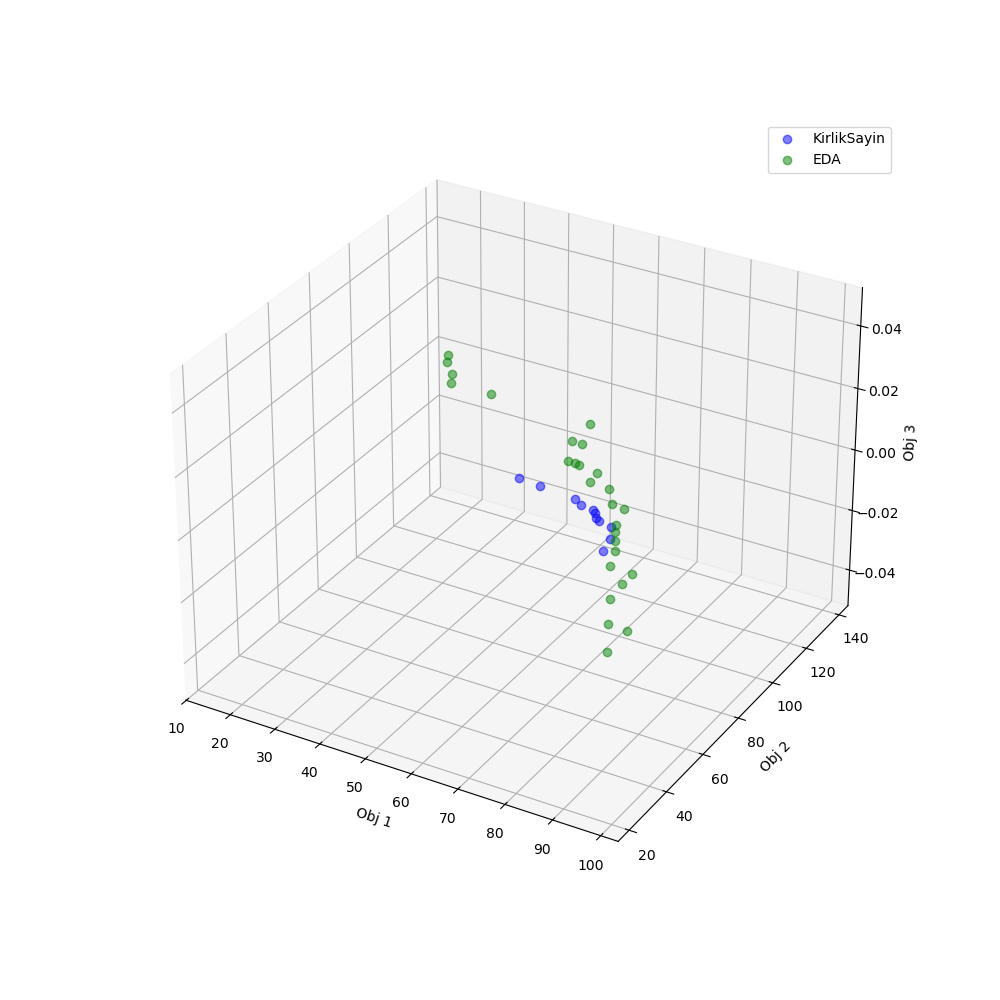

In [22]:
import matplotlib.pyplot as plt
%matplotlib widget
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')
ax.plot(pf_KirlikSayin[:,0], pf_KirlikSayin[:,1], 'bo', alpha=0.5, markersize=6, label="KirlikSayin")
ax.plot(pf_eda[:,0], pf_eda[:,1], 'go', alpha=0.5, markersize=6, label="EDA")
ax.set_xlabel('Obj 1')
ax.set_ylabel('Obj 2')
ax.set_zlabel('Obj 3')
ax.legend()
plt.show()

In [18]:
from pymoo.indicators.hv import HV

ref_point = np.zeros(n_obj)
hv = HV(ref_point=ref_point)
hv_pf_eda = hv(-pf_eda)
hv_pf_KirlikSayin = hv(-pf_KirlikSayin)
print(hv_pf_eda)
print(hv_pf_KirlikSayin)

10157.960700000001
6809.000000000001


In [19]:
def calculate_dominated(pf_predicted, pf_actual, n_obj):
    dominated = np.zeros(len(pf_predicted))
    for i in range(len(pf_predicted)):
        for j in range(len(pf_actual)):
            if np.all(pf_actual[j, :n_obj] >= pf_predicted[i, :n_obj]) and \
                np.any(pf_actual[j, :n_obj] > pf_predicted[i, :n_obj]):
                dominated[i] = 1
                break
    return np.sum(dominated), np.sum(dominated)/len(pf_predicted)

num_dominated, ratio_dominated = calculate_dominated(pf_eda, pf_KirlikSayin, 3)
print(num_dominated)
print(ratio_dominated)

0.0
0.0
